In [1]:
from os import listdir
import pandas as pd
import random
import seaborn as sns
import numpy as np

In [1]:
data = pd.DataFrame()
root = "/Users/bjcliang/Desktop/GSS/code"
files = listdir(root)
for num in files:
    if num.isnumeric():
        data_dir = [i for i in listdir(root+'/'+num) if ('csv' in i)][0]
        data_dir = root+'/'+num+'/'+data_dir
        df = pd.read_csv(data_dir)
        data = pd.concat([data, df])
        print(num, data.shape)
        print(set(df['dependent'].dropna()))

NameError: name 'pd' is not defined

In [37]:
data = data.dropna(subset=["year"])

In [4]:
set(data['dependent'])

{'FEAR',
 'GUN',
 'abortion',
 'citizen_violence',
 'coded_abortion',
 'coded_family_resp',
 'coded_gender_roles',
 'coded_sexual_morality',
 'official_violence',
 'physical',
 'satisfaction',
 'social'}

In [5]:
def code_temp(x):
    try: return int(float(x))
    except: return x

In [41]:
data['year'] = data['year'].apply(code_temp)
data['is_single_year'] = data['year'].apply(lambda x: str(x).isnumeric())
data['type'] = np.where(data['type']=='Time-forward Analysis', 
                        'Time-forward Analysis', 'original')

In [42]:
temp = data[(data['is_single_year'])].copy()
temp['year'] = temp['year'].apply(int)

### Finding 1
Out of the two studies that do report R^2 (5839, 3164), replication actually have higher R^2

In [33]:
set(data[(~data['r_sq'].isna()) & (data['type']=='original')]['dependent'])

{'coded_abortion',
 'coded_family_resp',
 'coded_gender_roles',
 'coded_sexual_morality',
 'physical',
 'social'}

<AxesSubplot:xlabel='type', ylabel='r_sq'>

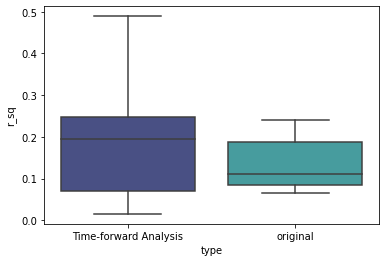

In [30]:
sns.boxplot(x='type', y='r_sq', 
              data=temp,
              palette = 'mako'
            )

<AxesSubplot:xlabel='type', ylabel='r_sq'>

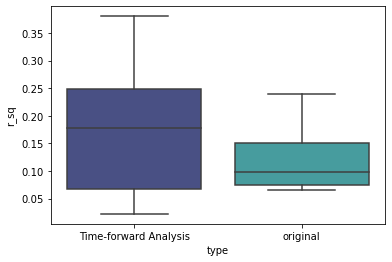

In [29]:
sns.boxplot(x='type', y='r_sq', 
              data=temp[temp['year'].isin(range(1976, 1988))],
              palette = 'mako'
            )

<AxesSubplot:xlabel='type', ylabel='r_sq'>

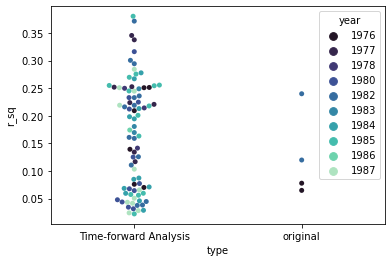

In [8]:
sns.swarmplot(x='type', y='r_sq', hue='year', 
              data=temp[temp['year'].isin(range(1976, 1988))],
              palette = 'mako'
            )

<AxesSubplot:xlabel='type', ylabel='r_sq'>

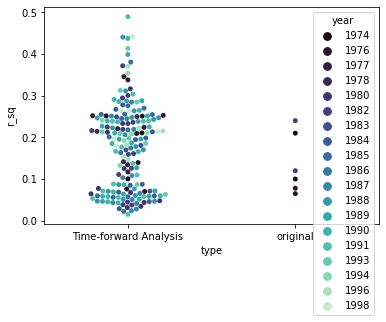

In [9]:
sns.swarmplot(x='type', y='r_sq', hue='year', palette = 'mako',
              data=temp)

### Finding 2
The size of the coefficients are about the same

In [44]:
coef = [i for i in data.columns if "_coefficient" in i]
data['size'] = data[coef].apply(lambda x: (np.mean([abs(float(i)) for i in x 
                                            if not str(i)[0].isalpha()])), axis=1)

<AxesSubplot:xlabel='type', ylabel='size'>

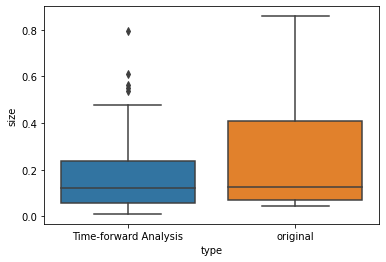

In [51]:
temp = data[(data['is_single_year'])].copy()
temp['year'] = temp['year'].apply(int)
sns.boxplot(x='type', y='size', 
              data=temp
            )

<AxesSubplot:xlabel='type', ylabel='size'>

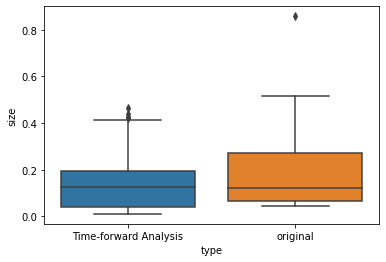

In [50]:
sns.boxplot(x='type', y='size', 
              data=temp[temp['year'].isin(range(1974, 1988))]
            )

<AxesSubplot:xlabel='type', ylabel='size'>

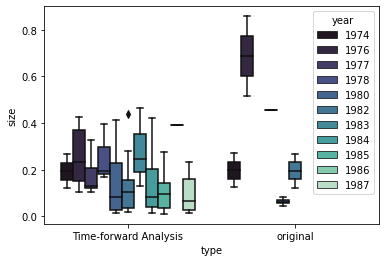

In [52]:
temp = data[(data['is_single_year'])].copy()
temp['year'] = temp['year'].apply(int)
sns.boxplot(x='type', y='size', hue='year', 
              data=temp[temp['year'].isin(range(1974, 1988))],
              palette = 'mako'
            )

### Finding 3
Original papers records a bit higher (but not significant) number of significant vars

<AxesSubplot:xlabel='type', ylabel='PROPSIG'>

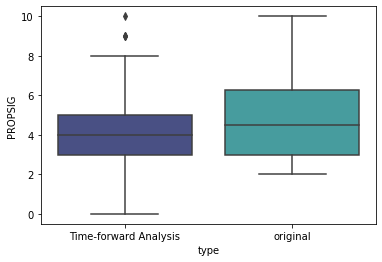

In [54]:
sns.boxplot(x='type', y='PROPSIG',
              data=temp, 
              palette = 'mako'
            )

In [82]:
temp[temp['type']=='original'][['dependent','PROPSIG']]

,dependent,PROPSIG
0,official_violence,10.0
1,citizen_violence,8.0
0,FEAR,5.0
1,GUN,6.0
2,FEAR,3.0
3,GUN,5.0
4,FEAR,3.0
5,GUN,4.0
0,physical,3.0
1,social,7.0


In [83]:
from scipy import stats
stats.ttest_ind(np.array(temp[temp['type']!='original']['PROPSIG']), 
                np.array(temp[temp['type']=='original']['PROPSIG'].dropna()))

Ttest_indResult(statistic=-1.5508280818874307, pvalue=0.12261576297907986)

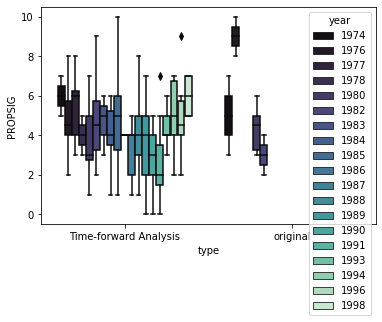

In [58]:
sns.boxplot(x='type', y='PROPSIG',
              data=temp, hue='year',
              palette = 'mako'
            )
ax.legend().set_visible(False)

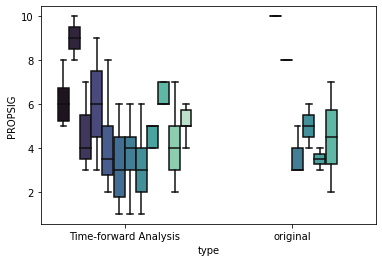

In [57]:
ax = sns.boxplot(x='type', y='PROPSIG',
            data=temp[temp['year'].isin(range(1974, 1988))],
            hue='dependent',
            palette = 'mako'
            )
ax.legend().set_visible(False)